In [1]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as pp

In [2]:
( c_1, c_2, x, delta, epsilon, alpha ) = sp.symbols( 'c_1, c_2, x, \Delta, \epsilon, \alpha' )

In [3]:
lim = epsilon / delta
res_1 = -1 / lim * sp.integrate( ( 1 - alpha ) * x, ( alpha, 0, lim ) )
print( sp.simplify( res_1 ) )

-x + \epsilon*x/(2*\Delta)


In [4]:
lim = 1
res_2 = -1 / lim * sp.integrate( ( 1 - alpha ) * x, ( alpha, 0, lim ) )
print( sp.simplify( res_2 ) )

-0.5*x


In [5]:
lim = ( delta + epsilon ) / delta
res_3 = -1 / ( 1 - lim ) * sp.integrate( ( 1 - alpha ) * x, ( alpha, lim, 1 ) )
print( sp.simplify( res_3 ) )

\epsilon*x/(2*\Delta)


In [6]:
sp.simplify( res_3 )

\epsilon*x/(2*\Delta)

In [7]:
def A_single( x, epsilon = 0.1, c_1 = 2.0, c_2 = 1.0 ):

    Delta = c_1 - ( c_2 + x )
    if Delta > epsilon:
        return -x * ( 1.0 - epsilon / ( 2.0 * Delta ) )
    elif Delta >= -epsilon:
        return -0.5 * x
    else:
        return x * epsilon / ( 2 * Delta )

def A( x, epsilon = 0.1, c_1 = 2.0, c_2 = 1.0 ):

    x_vec = np.ravel( x )
    retval = np.empty( x_vec.shape )
    for i in range( len( retval ) ):
        retval[ i ] = A_single( x_vec[ i ], epsilon, c_1, c_2 )
    
    return np.reshape( retval, x.shape )


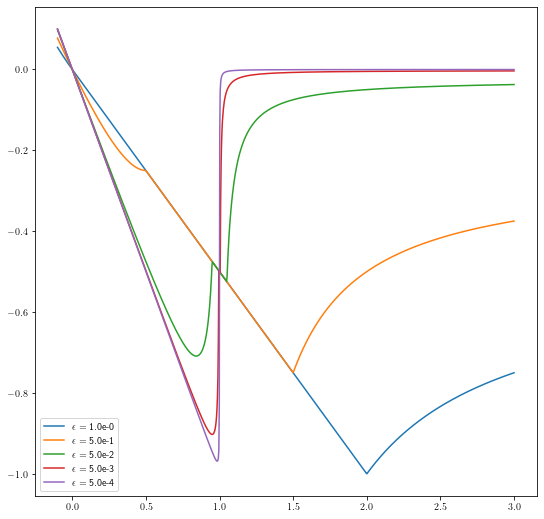

In [8]:
pp.figure( figsize = ( 9, 9 ) )

pp.rc( 'text', usetex = True )

x = np.linspace( -0.1, 3.0, 1000 )
epsilon_list = [ '1.0e-0', '5.0e-1', '5.0e-2', '5.0e-3', '5.0e-4' ]
for epsilon_str in epsilon_list:
    y = A( x, epsilon = float( epsilon_str ) )
    pp.plot( x, y )

pp.legend( [ '$\epsilon = {}$' + epsilon for epsilon in epsilon_list ] )

pp.savefig( 'grafico_a.pdf' )

pp.show()

In [9]:
def W_single( x, epsilon = 0.1, c_1 = 2.0, c_2 = 1.0 ):

    Delta = c_1 - ( c_2 + x )
    if Delta > epsilon:
        return -x * ( 1.0 - epsilon / Delta )
    else:
        return 0.0

def W( x, epsilon = 0.1, c_1 = 2.0, c_2 = 1.0 ):

    x_vec = np.ravel( x )
    retval = np.empty( x_vec.shape )
    for i in range( len( retval ) ):
        retval[ i ] = W_single( x_vec[ i ], epsilon, c_1, c_2 )
    
    return np.reshape( retval, x.shape )

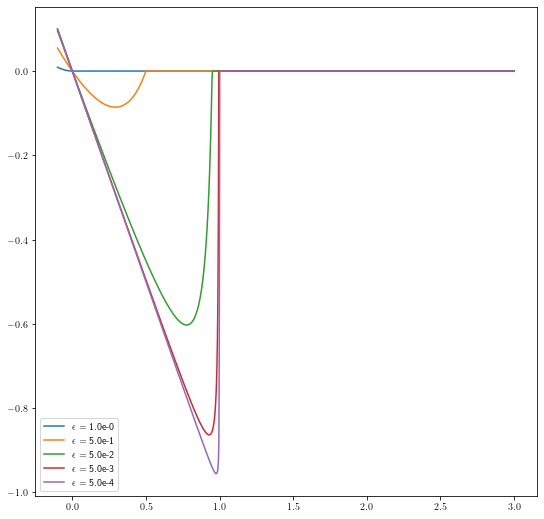

In [10]:
pp.figure( figsize = ( 9, 9 ) )

pp.rc( 'text', usetex = True )

x = np.linspace( -0.1, 3.0, 1000 )
epsilon_list = [ '1.0e-0', '5.0e-1', '5.0e-2', '5.0e-3', '5.0e-4' ]
for epsilon_str in epsilon_list:
    y = W( x, epsilon = float( epsilon_str ) )
    pp.plot( x, y )

pp.legend( [ '$\epsilon = {}$' + epsilon for epsilon in epsilon_list ] )

pp.savefig( 'grafico_w.pdf' )

pp.show()

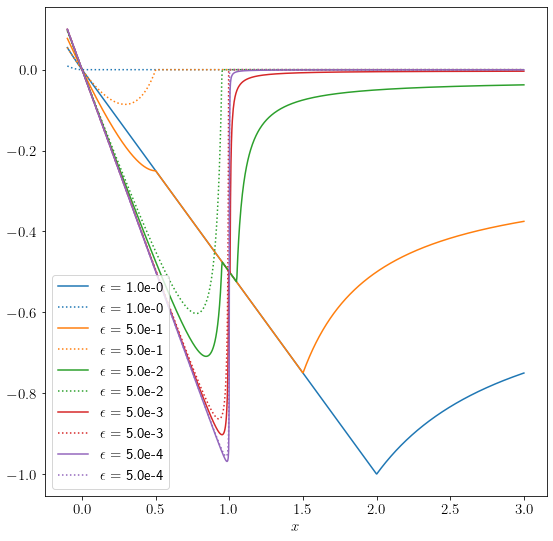

In [17]:
pp.figure( figsize = ( 9, 9 ) )

pp.rc( 'text', usetex = True )
pp.rc( 'font', size = 15 )

x = np.linspace( -0.1, 3.0, 1000 )
epsilon_list = [ '1.0e-0', '5.0e-1', '5.0e-2', '5.0e-3', '5.0e-4' ]
legend = []
for epsilon_str in epsilon_list:
    y = A( x, epsilon = float( epsilon_str ) )
    p = pp.plot( x, y )
    legend.append( '$\epsilon = {}$' + epsilon_str )
    y = W( x, epsilon = float( epsilon_str ) )
    pp.plot( x, y, ':', color = p[ -1 ].get_color() )
    legend.append( '$\epsilon = {}$' + epsilon_str )


pp.legend( legend )
pp.xlabel( '$x$' )

pp.savefig( 'grafico_aw.pdf' )

pp.show()